# Bonus: visualization of RT-DETRv2 internals

Inside the tuned RT-DETRv2 (`rtdetr-recipe_step2`, the best single model): the decoder query embeddings of the detections on a sample of val frames, projected to 2D with t-SNE and labelled by class, size, and error category, and the deformable cross-attention of the decoder: where each query samples the feature maps, how this changes over the 6 decoder layers, and how it relates to object size and scene density. W&B logging of curves, configs, and validation frames for every run is listed in `experiments/results.csv` (`wandb_url`).

| # | Section |
| --- | --- |
| 1 | [Setup](#1-setup) |
| 2 | [Queries of the sampled frames](#2-queries-of-the-sampled-frames) |
| 3 | [Query embeddings](#3-query-embeddings) |
| 4 | [Cross-attention of single queries](#4-cross-attention-of-single-queries) |
| 5 | [Cross-attention statistics](#5-cross-attention-statistics) |
| 6 | [Conclusions](#6-conclusions) |

## 1. Setup

Imports, data root from `DATA_ROOT`, the annotations of the adopted split, and the `best.pt` of `rtdetr-recipe_step2` (exists only on the PC). The model runs in eval mode at its training resolution (shorter side 1024 px, `max_size` 1824).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
import torch
from decouple import AutoConfig
from IPython.display import display
from tqdm.auto import tqdm

# make the repository root importable when the kernel starts in notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
# decouple locates .env from the caller file, which is a temp file inside a kernel
config = AutoConfig(search_path=PROJECT_ROOT)

import transformers
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from torchvision.io import ImageReadMode, decode_image

from src.data.annotations import load_annotations, load_split_clips
from src.data.classes import CLASS_NAMES
from src.evaluate import DATA_CONFIG_PATH, PREDICTIONS_FILE, RESULTS_PATH, find_run_dir
from src.evaluation.coco_metrics import PREDICTION_COLUMNS
from src.evaluation.failure_analysis import ERROR_CATEGORIES, find_best_f1_threshold, match_detections
from src.inference.torchvision_detectors import MODEL_STATE_KEY, convert_frames_to_inputs, select_device
from src.models.rtdetr import build_rtdetr, predict_query_internals, summarize_query_attention
from src.training.experiment import load_run_config
from src.visualization.frames import plot_query_attention
from src.visualization.plots import plot_embedding_panels
from src.visualization.style import (
    CLASS_COLORS,
    ERROR_CATEGORY_COLORS,
    FEATURE_LEVEL_COLORS,
    SIZE_BUCKET_COLORS,
    set_plot_theme,
)

# hide the checkpoint load report and progress bar of transformers in the saved outputs
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
set_plot_theme()
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

MODEL = "rtdetr-recipe_step2"
SEED = 42
FRAME_STEP = 10
tables = load_annotations(Path(config("DATA_ROOT")), load_split_clips(DATA_CONFIG_PATH))
val_images = tables.images.filter(pl.col("split") == "val")
val_objects = tables.objects.filter(pl.col("split") == "val")
run_dir = PROJECT_ROOT / find_run_dir(RESULTS_PATH, MODEL)
run_config = load_run_config(run_dir)
device = select_device()
detector = build_rtdetr(run_config)
checkpoint = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=True)
detector.load_state_dict(checkpoint[MODEL_STATE_KEY])
detector = detector.to(device).eval()
pl.DataFrame({"model": [MODEL], "device": [str(device)], "min_size": [detector.min_size], "max_size": [detector.max_size]})

model,device,min_size,max_size
str,str,i64,i64
"""rtdetr-recipe_step2""","""cuda""",1024,1824


## 2. Queries of the sampled frames

Every 10th val frame of each clip. A query is kept when its best class score reaches the score threshold that maximizes F1 at IoU 0.5 on all val frames (from the saved val predictions of the run), so the points are the detections the model would report. Each kept query is matched to the GT of its frame as in the failure analysis of `02_two_stage.ipynb` to `05_query_based.ipynb` (correct, duplicate, wrong class, poor localisation, background; detections in ignored regions are left out) and gets a size bucket from its box area (COCO ranges, small below 32² px², large from 96² px²).

In [2]:
saved_predictions = pl.read_parquet(run_dir / PREDICTIONS_FILE)
threshold = find_best_f1_threshold(match_detections(tables, "val", saved_predictions))["threshold"] or 0.0
sampled_images = val_images.filter((pl.col("frame_id") - 1) % FRAME_STEP == 0).sort("image_id")
objects_per_frame = val_objects.group_by("image_id").len("objects_in_frame")
# the sampled frame with the most labelled objects, kept for the single-query figures of section 4
dense_frame = (
    sampled_images.join(objects_per_frame, on="image_id")
    .sort("objects_in_frame", "image_id", descending=[True, False])
    .row(0, named=True)
)
pl.DataFrame(
    {
        "sampled frames": [sampled_images.height],
        "score threshold": [round(threshold, 4)],
        "densest sampled frame": [f"{dense_frame['clip']} frame {dense_frame['frame_id']}"],
        "objects in it": [dense_frame["objects_in_frame"]],
    }
)

sampled frames,score threshold,densest sampled frame,objects in it
i64,f64,str,i64
263,0.4536,"""uav0000137_00458_v frame 111""",113


In [3]:
query_tables, embeddings, attention_tables = [], [], []
for image_id, file_path in tqdm(sampled_images.select("image_id", "file_path").iter_rows(), total=sampled_images.height):
    frame = decode_image(file_path, mode=ImageReadMode.RGB)
    internals = predict_query_internals(detector, convert_frames_to_inputs([frame], device)[0])
    kept = internals.queries.filter(pl.col("score") >= threshold)
    query_tables.append(kept.with_columns(image_id=pl.lit(image_id)))
    embeddings.append(internals.embeddings[kept["query"].to_numpy()])
    attention_tables.append(
        summarize_query_attention(internals, kept["query"].to_list()).with_columns(image_id=pl.lit(image_id))
    )
    if image_id == dense_frame["image_id"]:
        dense_internals = internals
kept_queries = pl.concat(query_tables).with_row_index("point")
embedding_matrix = np.concatenate(embeddings)
attention = pl.concat(attention_tables)
pl.DataFrame({"kept queries": [kept_queries.height], "embedding size": [embedding_matrix.shape[1]]})

kept queries,embedding size
i64,i64
10276,256


In [4]:
sampled_tables = tables._replace(
    images=tables.images.filter(pl.col("split") == "val", pl.col("image_id").is_in(sampled_images["image_id"].to_list()))
)
matched = match_detections(sampled_tables, "val", kept_queries).detections
area = pl.col("w") * pl.col("h")
points = (
    matched.filter(pl.col("category") != "ignored")
    .join(objects_per_frame, on="image_id", how="left")
    .with_columns(
        predicted_class=pl.col("class_id").replace_strict(dict(enumerate(CLASS_NAMES))),
        gt_class=pl.col("best_class_id").replace_strict(dict(enumerate(CLASS_NAMES)), default=None),
        size_bucket=pl.when(area < 32**2).then(pl.lit("small")).when(area < 96**2).then(pl.lit("medium")).otherwise(pl.lit("large")),
        objects_in_frame=pl.col("objects_in_frame").fill_null(0),
    )
    .sort("point")
)
points.group_by("category").len().sort(pl.col("category").cast(pl.Enum(ERROR_CATEGORIES)))

category,len
str,u32
"""correct""",6968
"""duplicate""",56
"""wrong_class""",766
"""poor_localisation""",925
"""background""",959


*Takeaway:* at the best-F1 threshold 0.4536, 10,276 queries are kept on 263 frames; 602 fall in ignored regions and are left out, leaving 9,674 points. Of these, 72.0% are correct, 9.9% background, 9.6% poor localisation, 7.9% wrong class and 0.6% duplicates. The low duplicate share is expected from a set-prediction decoder without NMS.

## 3. Query embeddings

The 256-dimensional output of the last decoder layer of every kept query, reduced to 50 dimensions with PCA and projected to 2D with t-SNE ([scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html); [van der Maaten and Hinton, 2008](https://jmlr.org/papers/v9/vandermaaten08a.html)). t-SNE keeps neighbourhoods, not distances ([Wattenberg et al., 2016](https://distill.pub/2016/misread-tsne/)): clusters and their members are meaningful, the distance between clusters and the cluster sizes are not. The class head is a linear layer on this embedding, so classes the model separates well must form separate regions.

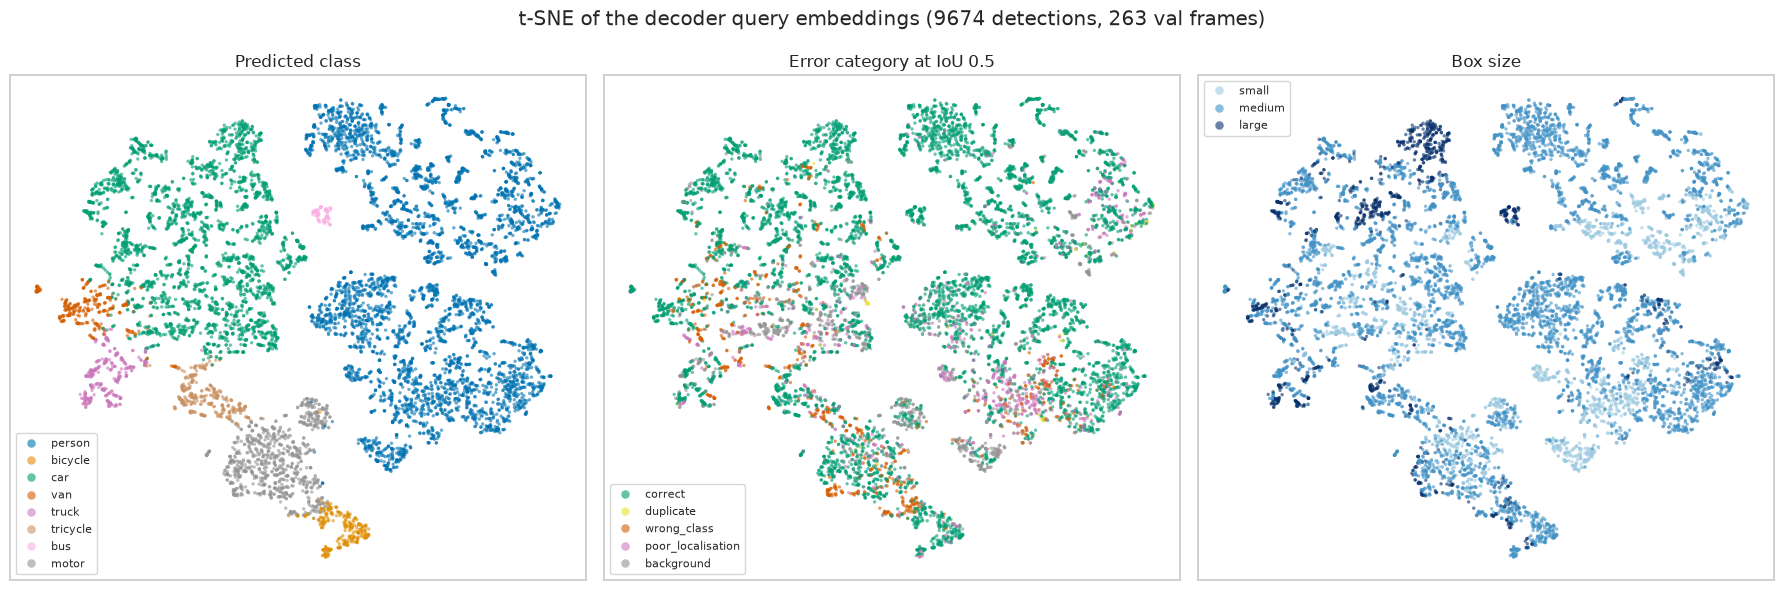

In [5]:
embedding_values = embedding_matrix[points["point"].to_numpy()]
reduced = PCA(n_components=50, random_state=SEED).fit_transform(embedding_values)
projected = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(reduced)
points = points.with_columns(embedding_x=pl.Series(projected[:, 0]), embedding_y=pl.Series(projected[:, 1]))
fig = plot_embedding_panels(
    points,
    [
        ("predicted_class", CLASS_COLORS, "Predicted class"),
        ("category", ERROR_CATEGORY_COLORS, "Error category at IoU 0.5"),
        ("size_bucket", SIZE_BUCKET_COLORS, "Box size"),
    ],
    f"t-SNE of the decoder query embeddings ({points.height} detections, {sampled_images.height} val frames)",
)

*Takeaway:* the embedding is organised by class first. Person and car each form large regions, bus is a small isolated cluster, and van and truck sit at the edge of the car region. Bicycle, motor and tricycle form one chain, which matches the two-wheeler confusions below. Inside each class region, small and medium boxes occupy different parts of the region, so size is the second factor. Poor-localisation and background points are not a separate cluster: they lie inside the class regions, mostly where small person boxes and the car / van / truck boundary are, so the last decoder layer represents these errors like real objects of that class.

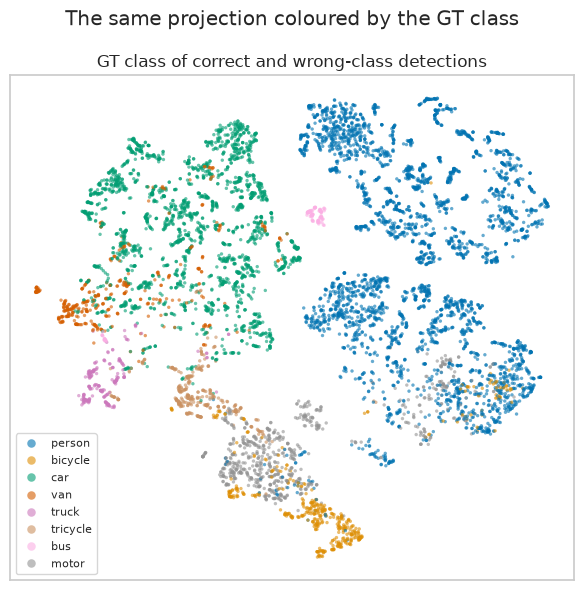

In [6]:
fig = plot_embedding_panels(
    points.filter(pl.col("category").is_in(["correct", "wrong_class"])),
    [
        ("gt_class", CLASS_COLORS, "GT class of correct and wrong-class detections"),
    ],
    "The same projection coloured by the GT class",
)

*Takeaway:* coloured by GT class, the wrong-class points show where the confusions sit. Van GT points are spread through the car region, and motor and bicycle GT points appear inside the person region. A hypothesis for the second case: riders and their vehicles overlap almost completely from a drone view, so a query on a rider box can match the two-wheeler GT box at IoU 0.5.

Quantitative check in the full 256-dimensional space: for each correct detection, the share of its 10 nearest neighbours (Euclidean, other detections of the sample) that are correct detections of the same class, and the class-to-class share of neighbours. Off-diagonal entries are the confusable classes.

In [7]:
correct = points.filter(pl.col("category") == "correct")
correct_values = embedding_matrix[correct["point"].to_numpy()]
neighbours = NearestNeighbors(n_neighbors=11).fit(correct_values).kneighbors(correct_values, return_distance=False)[:, 1:]
classes = correct["class_id"].to_numpy()
neighbour_classes = classes[neighbours]
neighbour_share = pl.DataFrame(
    [
        {"class": CLASS_NAMES[c], "detections": int((classes == c).sum())}
        | {CLASS_NAMES[o]: float((neighbour_classes[classes == c] == o).mean()) for o in range(len(CLASS_NAMES))}
        for c in range(len(CLASS_NAMES))
        if (classes == c).any()
    ]
)
neighbour_share.with_columns(pl.selectors.float().round(3))

class,detections,person,bicycle,car,van,truck,tricycle,bus,motor
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""person""",3502,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""bicycle""",224,0.0,0.997,0.0,0.0,0.0,0.0,0.0,0.003
"""car""",2035,0.0,0.0,0.998,0.002,0.0,0.0,0.0,0.0
"""van""",200,0.0,0.0,0.016,0.983,0.0,0.0,0.0,0.0
"""truck""",180,0.0,0.0,0.004,0.001,0.992,0.003,0.0,0.0
"""tricycle""",233,0.0,0.0,0.003,0.0,0.0,0.991,0.0,0.006
"""bus""",81,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
"""motor""",513,0.001,0.003,0.0,0.0,0.0,0.002,0.0,0.995


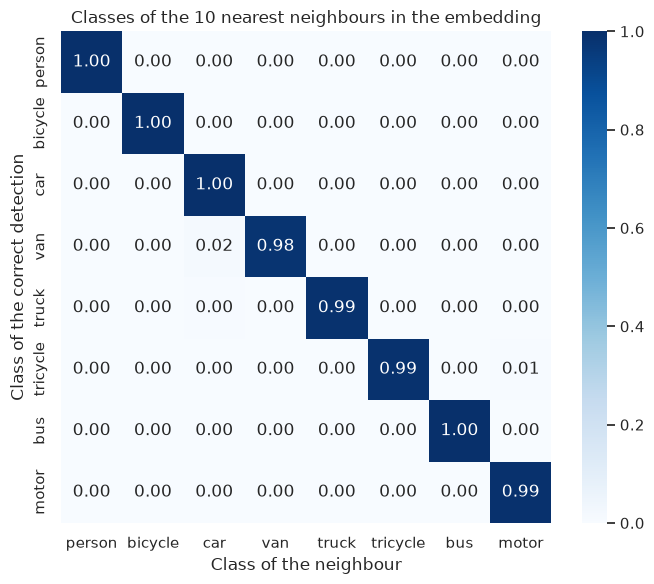

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    neighbour_share.select(CLASS_NAMES).to_numpy(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
    xticklabels=CLASS_NAMES, yticklabels=neighbour_share["class"].to_list(), ax=ax,
)
ax.set(xlabel="Class of the neighbour", ylabel="Class of the correct detection", title="Classes of the 10 nearest neighbours in the embedding")
fig.tight_layout()

*Takeaway:* for correct detections, at least 98.3% of the 10 nearest neighbours in the full 256-dimensional space share the class, for every class. The largest off-diagonal shares are van to car (0.016) and tricycle to motor (0.006). This is an upper bound on separability: frames are sampled every 10 frames, so neighbours can be the same physical object in another frame of the clip.

In [9]:
points.filter(pl.col("category") == "wrong_class").group_by("gt_class", "predicted_class").len().sort("len", descending=True).head(10)

gt_class,predicted_class,len
str,str,u32
"""van""","""car""",184
"""bicycle""","""motor""",147
"""motor""","""person""",133
"""car""","""van""",57
"""person""","""motor""",29
"""bicycle""","""person""",25
"""tricycle""","""truck""",23
"""motor""","""tricycle""",21
"""bicycle""","""tricycle""",21


*Takeaway:* the three largest confusions are van predicted as car (184), bicycle as motor (147) and motor as person (133); together they are 60% of the 766 wrong-class detections. All three are pairs that are adjacent or overlapping in the t-SNE map.

## 4. Cross-attention of single queries

RT-DETRv2 has no dense attention map in the decoder: its multi-scale deformable cross-attention ([Zhu et al., 2021](https://arxiv.org/abs/2010.04159); RT-DETRv2: [Lv et al., 2024](https://arxiv.org/abs/2407.17140)) lets each query sample 4 locations per head (8 heads) on each of the 3 feature levels (strides 8, 16, 32), offset from its current reference box, and weights them. The panels show these 96 locations per query on the sampled frame with the most labelled objects, coloured by level, with an area proportional to the weight, together with the box of that decoder layer. Queries: the highest-scoring correct detection of each size bucket and the highest-scoring background detection.

query,predicted_class,score,category,size_bucket,w,h
i64,str,f64,str,str,f64,f64
1,"""car""",0.908085,"""correct""","""large""",277.558228,164.893677
8,"""car""",0.858791,"""correct""","""medium""",104.824707,71.267487
35,"""person""",0.725898,"""background""","""large""",78.540405,133.132324


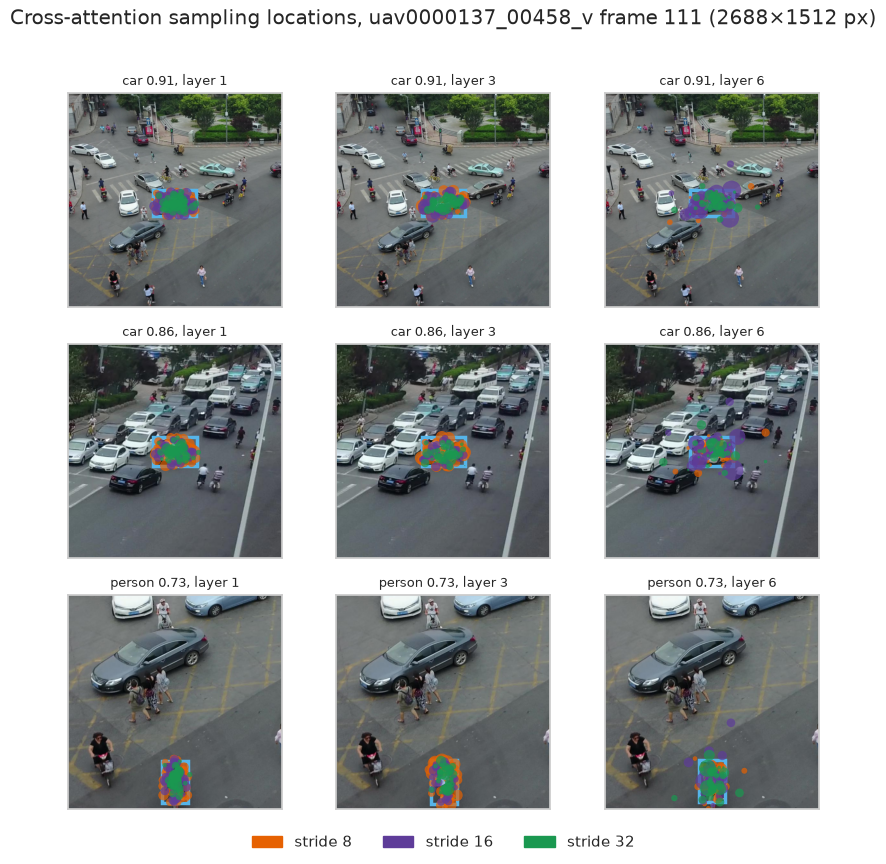

In [10]:
dense_points = points.filter(pl.col("image_id") == dense_frame["image_id"])
example_queries = pl.concat(
    [
        dense_points.filter(pl.col("category") == "correct").sort("score", descending=True).unique("size_bucket", keep="first", maintain_order=True),
        dense_points.filter(pl.col("category") == "background").sort("score", descending=True).head(1),
    ]
)
display(example_queries.select("query", "predicted_class", "score", "category", "size_bucket", "w", "h"))
fig = plot_query_attention(
    Path(dense_frame["file_path"]), dense_internals, example_queries["query"].to_list(), [0, 2, 5], 5.0, 160
)
fig.suptitle(f"Cross-attention sampling locations, {dense_frame['clip']} frame {dense_frame['frame_id']} ({dense_frame['width']}×{dense_frame['height']} px)")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))

*Takeaway:* the densest sampled frame (113 objects) has no correct small detection above the threshold, so only large and medium correct queries are shown. In layer 1 the sampling locations are packed inside the reference box at all three levels. By layer 6 they spread beyond the box onto the surroundings (road, neighbouring cars), mostly at stride 16, while the box itself barely changes after layer 3. The background query covers a visible pedestrian; it has no GT box, so this is possibly an unlabelled person rather than a true false positive; not verified.

## 5. Cross-attention statistics

Per kept query and decoder layer (`summarize_query_attention`): the share of attention on locations inside the final box, the spread of the locations around the box centre relative to the box size, and the attention share of each feature level, averaged over the 8 heads. Correct detections only, by size bucket, then by scene density.

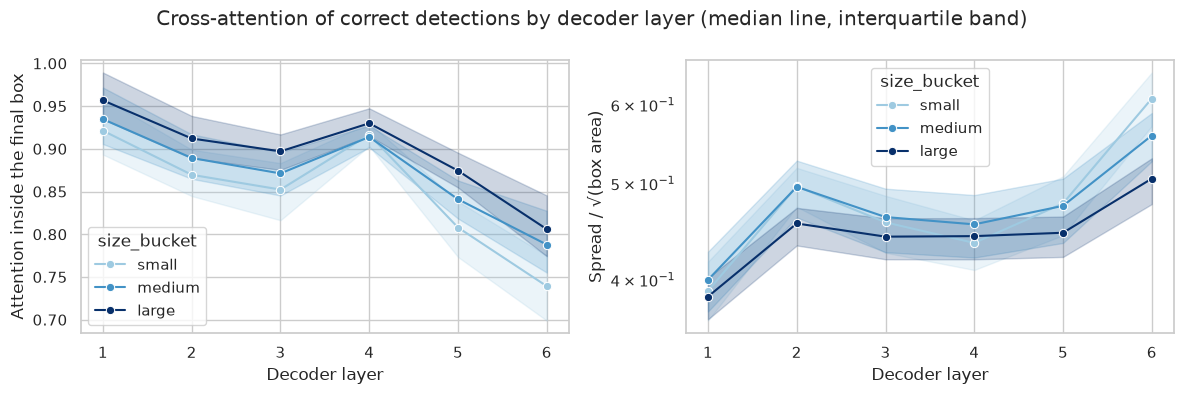

In [11]:
attention_points = attention.join(
    points.select("image_id", "query", "category", "size_bucket", "predicted_class", "objects_in_frame"),
    on=["image_id", "query"],
)
correct_attention = attention_points.filter(pl.col("category") == "correct").with_columns(decoder_layer=pl.col("layer") + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in ((axes[0], "inside_share", "Attention inside the final box"), (axes[1], "spread", "Spread / √(box area)")):
    sns.lineplot(
        correct_attention.select("decoder_layer", "size_bucket", column).to_dict(as_series=False),
        x="decoder_layer", y=column, hue="size_bucket", hue_order=list(SIZE_BUCKET_COLORS),
        palette=SIZE_BUCKET_COLORS, marker="o", errorbar=("pi", 50), ax=ax,
    )
    ax.set(xlabel="Decoder layer", ylabel=label)
axes[1].set_yscale("log")
fig.suptitle("Cross-attention of correct detections by decoder layer (median line, interquartile band)")
fig.tight_layout()

*Takeaway:* the share of attention inside the final box falls from 0.92 to 0.96 in layer 1 to 0.74 to 0.81 in layer 6, and the spread rises from about 0.39 of √(box area) in layer 1 to 0.50 (large) and 0.61 (small) in layer 6. The drop is not monotone: layer 4 returns to about 0.91 to 0.93 inside the box. Small objects end with the least attention inside the box (median 0.74) and the largest relative spread (0.61): the last layers look at context around small boxes, in absolute pixels still a small neighbourhood.

In [12]:
level_columns = [c for c in attention.columns if c.startswith("level_share_")]
level_table = (
    correct_attention.filter(pl.col("layer") == pl.col("layer").max())
    .group_by("size_bucket").agg(pl.len().alias("detections"), *(pl.col(c).mean().round(3) for c in level_columns))
    .sort(pl.col("size_bucket").cast(pl.Enum(list(SIZE_BUCKET_COLORS))))
)
level_table

size_bucket,detections,level_share_8,level_share_16,level_share_32
str,u32,f32,f32,f32
"""small""",1001,0.419,0.326,0.255
"""medium""",5000,0.348,0.355,0.297
"""large""",967,0.253,0.464,0.282


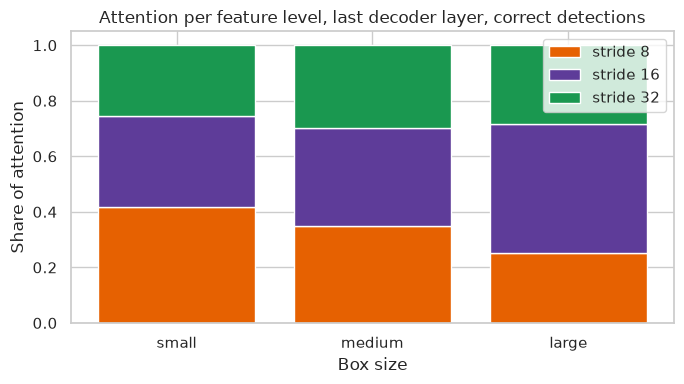

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(level_table.height)
for column, color in zip(level_columns, FEATURE_LEVEL_COLORS, strict=True):
    values = level_table[column].to_numpy()
    ax.bar(level_table["size_bucket"].to_list(), values, bottom=bottom, color=color, label=column.replace("level_share_", "stride "))
    bottom += values
ax.set(xlabel="Box size", ylabel="Share of attention", title="Attention per feature level, last decoder layer, correct detections")
ax.legend()
fig.tight_layout()

*Takeaway:* the level shares follow object size: stride 8 gets the largest share for small objects (0.42 vs 0.25 for large), stride 16 for large objects (0.46). Stride 32 stays at 0.26 to 0.30 for every size. Unlike the FPN level assignment of Faster R-CNN, where each RoI is pooled from one level, every query reads all three levels and only shifts its weights.

In [14]:
objects = pl.col("objects_in_frame")
last_layer = correct_attention.filter(pl.col("layer") == pl.col("layer").max()).with_columns(
    density=pl.when(objects < 20).then(pl.lit("< 20 objects"))
    .when(objects < 50).then(pl.lit("20 to 49"))
    .when(objects < 100).then(pl.lit("50 to 99"))
    .otherwise(pl.lit("≥ 100"))
    .cast(pl.Enum(["< 20 objects", "20 to 49", "50 to 99", "≥ 100"]))
)
last_layer.group_by("density", "size_bucket").agg(
    pl.len().alias("detections"),
    pl.col("inside_share").median().round(3),
    pl.col("spread").median().round(3),
).sort("size_bucket", "density").pivot("density", index="size_bucket", values=["inside_share", "spread"])

size_bucket,inside_share_< 20 objects,inside_share_20 to 49,inside_share_50 to 99,inside_share_≥ 100,spread_< 20 objects,spread_20 to 49,spread_50 to 99,spread_≥ 100
str,f32,f32,f32,f32,f64,f64,f64,f64
"""large""",0.764,0.818,0.813,0.811,0.477,0.491,0.498,0.522
"""medium""",0.683,0.792,0.796,0.771,0.571,0.556,0.558,0.556
"""small""",0.68,0.748,0.733,null,0.639,0.604,0.606,null


*Takeaway:* the effect of scene density is small. Correct detections in frames with fewer than 20 objects have the least attention inside the box (0.68 to 0.76) and, for small objects, the largest spread (0.64 vs about 0.60 in denser frames). There is no small detection in frames with 100 or more objects at this threshold. A hypothesis: sparse frames are often low-altitude views where the surroundings carry more context; this was not tested.

In [15]:
by_category = attention_points.filter(pl.col("layer") == pl.col("layer").max()).group_by("category").agg(
    pl.len().alias("detections"),
    pl.col("inside_share").median().round(3),
    pl.col("spread").median().round(3),
    *(pl.col(c).mean().round(3) for c in level_columns),
).sort(pl.col("category").cast(pl.Enum(ERROR_CATEGORIES)))
by_category

category,detections,inside_share,spread,level_share_8,level_share_16,level_share_32
str,u32,f32,f64,f32,f32,f32
"""correct""",6968,0.783,0.556,0.345,0.366,0.289
"""duplicate""",56,0.765,0.567,0.367,0.364,0.268
"""wrong_class""",766,0.783,0.546,0.389,0.349,0.262
"""poor_localisation""",925,0.767,0.566,0.404,0.33,0.266
"""background""",959,0.768,0.566,0.396,0.327,0.277


*Takeaway:* the attention statistics barely separate errors from correct detections: inside share 0.765 to 0.783 and spread 0.546 to 0.567 for every category. Errors put more weight on stride 8 (0.39 to 0.40 vs 0.345), which is consistent with errors being more often small boxes rather than with a different attention pattern; size is not controlled in this table.

## 6. Conclusions

Measured on 263 val frames of `rtdetr-recipe_step2`:

1. The last-layer query embedding is organised by class, then by size. Correct detections have at least 98% same-class neighbours, an upper bound since one object appears in several sampled frames.
2. The confusions visible in the embedding (van and car; bicycle, motor and person) are the three largest wrong-class pairs, 60% of wrong-class detections.
3. Poor-localisation and background detections are embedded inside the regions of real objects of their class, so the embedding alone cannot flag them.
4. Deformable cross-attention starts inside the box and widens over the decoder layers, most for small objects (median 0.74 inside the box and 0.61 √(box area) spread at layer 6).
5. Feature levels are shared, not assigned: small objects lean on stride 8 and large objects on stride 16, while stride 32 keeps about 0.28 for every size.

Hypotheses, not tested here: the rider and two-wheeler confusion comes from box overlap in the drone view, and the wider context in later layers helps small objects where the box itself has few pixels.